# Performance–Cost Analysis

Addresses three reviewer questions:
1. **Table 1 — MPC variants**: reward vs. average decision latency for MPC(H=10), MPC(H=25), MPCTimeBinned(H=10,K=2), MPCTimeBinned(H=25,K=2).
2. **Table 2 — Planning vs. myopic**: full reward–cost spectrum from FiPla (cheapest) to MPCTimeBinned (most expensive).
3. **Table 3 — Deep RL vs. MPC**: training cost + per-decision inference latency comparison.

Latency measured on the Margaret cluster (`normal-best` partition, 4 CPUs), 100 seeds,
`survival-second-price-exponential` (η=50) for MPC/Shading/baselines.
RL inference measured on the same hardware with models trained on robustness scenarios.

In [1]:
import sys, pathlib, os
# Notebooks live in benchmark/notebooks/; go two levels up to reach repo root
_nb_file = globals().get('__vsc_ipynb_file__') or __file__
repo_root = pathlib.Path(_nb_file).resolve().parent.parent.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
os.chdir(repo_root)

In [2]:
%matplotlib inline
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from IPython.display import display

## Load timing CSVs

Each CSV was produced by a dedicated SLURM job (`run_timing_*.sh`) on 100 seeds.
The `bid_time_s` column records `time.perf_counter()` wall-clock seconds for each `policy.bid(obs)` call.

In [3]:
TIMING_DIR = repo_root / 'benchmark/benchmark_results/timing'

# n_rollouts used per policy type (all sim-based policies use 10; RL/FiPla don't use rollouts)
N_ROLLOUTS = {
    'FiPla':                    None,
    'GreedyMyopic':             10,
    'Shading(α=0.7)':           10,
    'MPC(H=10)':                10,
    'MPC(H=25)':                10,
    'MPCTimeBinned(H=10,K=2)':  10,
    'MPCTimeBinned(H=25,K=2)':  10,
    'PPO':                      None,
    'SAC':                      None,
    'TD3':                      None,
}

# timing_td3.csv was produced by run_timing_rl.sh with ALGO=td3 and a TD3 model path,
# but SB3 stores the algorithm class name inside the checkpoint, so the policy column
# in the CSV reads "SAC" instead of "TD3". Relabel it here.
_SOURCE_RELABEL = {'timing_td3': {'SAC': 'TD3'}}

records = []
for f in sorted(TIMING_DIR.glob('timing_*.csv')):
    df = pd.read_csv(f)
    if 'bid_time_s' not in df.columns:
        print(f'  [WARNING] {f.name} has no bid_time_s column — skipping')
        continue
    relabel = _SOURCE_RELABEL.get(f.stem, {})
    if relabel:
        df['policy'] = df['policy'].replace(relabel)
        print(f'  [{f.name}] relabelled policy: {relabel}')
    ep_reward = (
        df.sort_values(['policy', 'seed', 'step'])
        .groupby(['policy', 'seed'])['cum_reward'].last()
        .reset_index()
    )
    for pol, grp in ep_reward.groupby('policy'):
        t_ms = df[df['policy'] == pol]['bid_time_s'].mean() * 1000
        records.append({
            'policy':       pol,
            'n_rollouts':   N_ROLLOUTS.get(pol, None),
            'source':       f.stem,
            'mean_reward':  grp['cum_reward'].mean(),
            'std_reward':   grp['cum_reward'].std(),
            'avg_bid_ms':   t_ms,
        })
        nr = N_ROLLOUTS.get(pol)
        print(f'  {pol:35s}  reward={grp["cum_reward"].mean():.3f}  latency={t_ms:.3f} ms  n_rollouts={nr}')

timing = pd.DataFrame(records).sort_values('avg_bid_ms').reset_index(drop=True)
print(f'\nLoaded {len(timing)} policy entries from {TIMING_DIR}')

  FiPla                                reward=1.606  latency=0.001 ms  n_rollouts=None
  GreedyMyopic                         reward=1.447  latency=32.946 ms  n_rollouts=10
  MPC(H=10)                            reward=1.958  latency=93.655 ms  n_rollouts=10
  MPC(H=25)                            reward=2.227  latency=172.811 ms  n_rollouts=10
  MPCTimeBinned(H=10,K=2)              reward=1.996  latency=470.206 ms  n_rollouts=10
  MPCTimeBinned(H=25,K=2)              reward=2.278  latency=834.841 ms  n_rollouts=10
  PPO                                  reward=1.457  latency=0.232 ms  n_rollouts=None
  SAC                                  reward=1.572  latency=0.328 ms  n_rollouts=None
  Shading(α=0.7)                       reward=1.673  latency=32.438 ms  n_rollouts=10
  [timing_td3.csv] relabelled policy: {'SAC': 'TD3'}
  TD3                                  reward=0.264  latency=0.365 ms  n_rollouts=None

Loaded 10 policy entries from /home/epatard/Bureau/Inria/paper_ready_code/dynam

---
## 1. MPC variants: performance–cost tradeoff

All four MPC variants evaluated on `survival-second-price-exponential` (η=50), 100 seeds, `n_rollouts=10`, `|A|=5` alpha candidates.
Decision latency scales with planning horizon H and number of time bins K.

In [4]:
_mpc_policies = ['MPC(H=10)', 'MPC(H=25)', 'MPCTimeBinned(H=10,K=2)', 'MPCTimeBinned(H=25,K=2)']
_mpc = timing[timing['policy'].isin(_mpc_policies)].copy()

_mpc['H'] = _mpc['policy'].str.extract(r'H=(\d+)').astype(float).astype('Int64')
_mpc['K'] = _mpc['policy'].str.extract(r'K=(\d+)').fillna(1).astype(float).astype('Int64')
_mpc['relative_cost'] = (_mpc['avg_bid_ms'] / _mpc['avg_bid_ms'].min()).round(1)

tbl1 = _mpc[['policy', 'H', 'K', 'n_rollouts', 'mean_reward', 'std_reward', 'avg_bid_ms', 'relative_cost']].copy()
tbl1.columns = ['Policy', 'H', 'K (bins)', 'n_rollouts', 'Mean reward', 'Std reward', 'Avg bid latency (ms)', 'Relative cost']
tbl1 = tbl1.sort_values('Avg bid latency (ms)').reset_index(drop=True)

display(
    tbl1.style
    .format({'Mean reward': '{:.3f}', 'Std reward': '{:.3f}',
             'Avg bid latency (ms)': '{:.1f}', 'Relative cost': '{:.1f}×'})
    .background_gradient(subset=['Mean reward'], cmap='YlGn')
    .background_gradient(subset=['Avg bid latency (ms)', 'Relative cost'], cmap='YlOrRd')
    .set_caption('Table 1 — MPC variants: performance vs. decision latency '
                 '(survival-second-price-exponential, η=50, 100 seeds, n_rollouts=10)')
    .set_properties(**{'text-align': 'center'})
)

,Policy,H,K (bins),n_rollouts,Mean reward,Std reward,Avg bid latency (ms),Relative cost
0,MPC(H=10),10,1,10.000000,1.958,1.742,93.7,1.0×
1,MPC(H=25),25,1,10.000000,2.227,2.151,172.8,1.8×
2,"MPCTimeBinned(H=10,K=2)",10,2,10.000000,1.996,1.758,470.2,5.0×
3,"MPCTimeBinned(H=25,K=2)",25,2,10.000000,2.278,2.255,834.8,8.9×


**Relative cost** is the ratio of a variant's average bid latency to the fastest MPC variant's latency (here `MPC(H=10)`):

$$\text{Relative cost} = \frac{\text{avg bid latency (variant)}}{\text{avg bid latency (cheapest MPC variant)}}$$

A value of `1.0×` means the variant is as fast as the cheapest MPC evaluated; `2.0×` means twice as slow per decision step. It is a dimensionless measure of the additional per-decision compute budget relative to the simplest planning baseline.

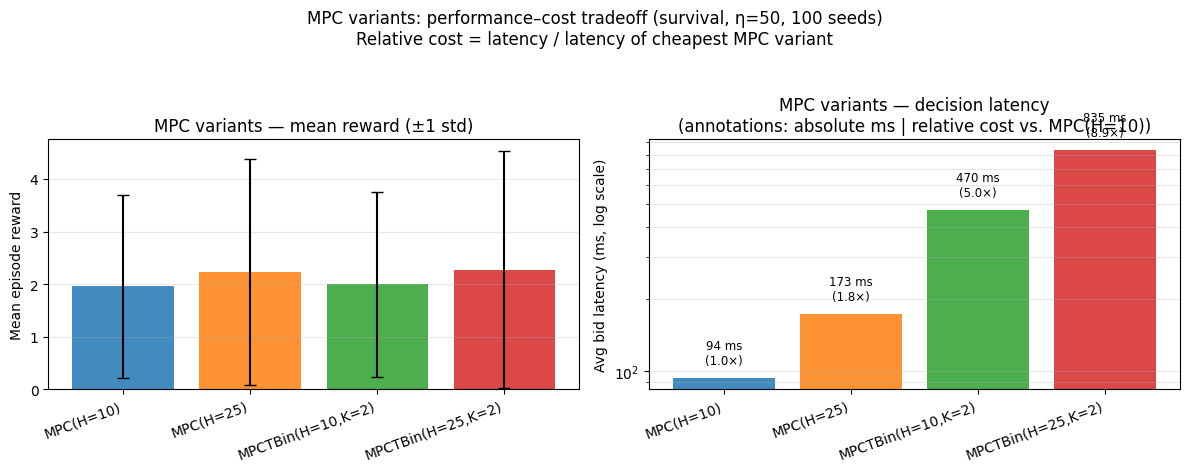

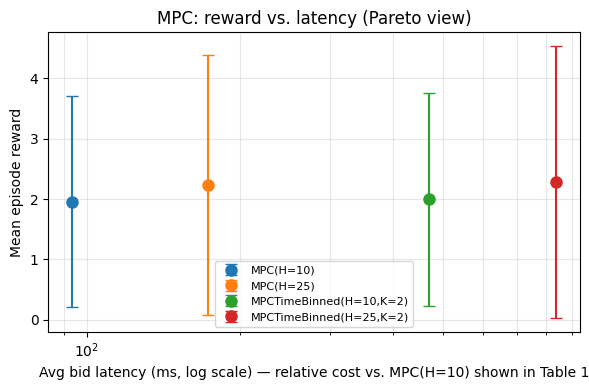

In [5]:
if len(_mpc) < 2:
    print('Not enough MPC variants yet — waiting for mpcbin jobs to finish.')
else:
    _mpc_sorted = _mpc.sort_values('avg_bid_ms').reset_index(drop=True)
    _labels = [p.replace('MPCTimeBinned', 'MPCTBin') for p in _mpc_sorted['policy']]
    _colors_mpc = ['C0', 'C1', 'C2', 'C3'][:len(_mpc_sorted)]
    _x = np.arange(len(_mpc_sorted))
    _cheapest_ms = _mpc_sorted['avg_bid_ms'].min()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    # Left: reward bar chart with ±1 std error bars
    axes[0].bar(_x, _mpc_sorted['mean_reward'], color=_colors_mpc,
                yerr=_mpc_sorted['std_reward'], capsize=4, alpha=0.85)
    axes[0].set_xticks(_x); axes[0].set_xticklabels(_labels, rotation=20, ha='right')
    axes[0].set_ylabel('Mean episode reward')
    axes[0].set_title('MPC variants — mean reward (±1 std)')
    axes[0].grid(True, axis='y', alpha=0.3)

    # Right: avg bid latency bar chart (log scale)
    # Annotations show absolute latency and relative cost vs. cheapest MPC variant
    axes[1].bar(_x, _mpc_sorted['avg_bid_ms'], color=_colors_mpc, alpha=0.85)
    axes[1].set_xticks(_x); axes[1].set_xticklabels(_labels, rotation=20, ha='right')
    axes[1].set_ylabel('Avg bid latency (ms, log scale)')
    axes[1].set_title('MPC variants — decision latency\n'
                      '(annotations: absolute ms | relative cost vs. MPC(H=10))')
    axes[1].set_yscale('log')
    axes[1].grid(True, axis='y', alpha=0.3, which='both')
    for i, (ms, rel) in enumerate(zip(_mpc_sorted['avg_bid_ms'], _mpc_sorted['relative_cost'])):
        axes[1].text(i, ms * 1.15, f'{ms:.0f} ms\n({rel:.1f}×)', ha='center', fontsize=8.5)

    plt.suptitle('MPC variants: performance–cost tradeoff (survival, η=50, 100 seeds)\n'
                 'Relative cost = latency / latency of cheapest MPC variant', y=1.04)
    plt.tight_layout()
    plt.savefig('mpc_performance_cost_bars.pdf')
    plt.show()

    # Scatter: Pareto view
    fig, ax = plt.subplots(figsize=(6, 4))
    for i, row in _mpc_sorted.iterrows():
        ax.errorbar(row['avg_bid_ms'], row['mean_reward'],
                    yerr=row['std_reward'], fmt='o', color=_colors_mpc[i],
                    capsize=4, markersize=8, label=row['policy'])
    ax.set_xlabel('Avg bid latency (ms, log scale) — relative cost vs. MPC(H=10) shown in Table 1')
    ax.set_ylabel('Mean episode reward')
    ax.set_xscale('log')
    ax.set_title('MPC: reward vs. latency (Pareto view)')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, which='both')
    plt.tight_layout()
    plt.savefig('mpc_performance_cost_scatter.pdf')
    plt.show()

---
## 2. Full planning vs. myopic: reward–cost spectrum

Comparing all non-RL policies from cheapest (FiPla, ~0.001 ms) to most expensive (MPCTimeBinned).
Shows the marginal reward gain from adding a planning horizon over myopic-optimal decisions.

In [6]:
_non_rl = timing[~timing['policy'].isin(['PPO', 'SAC', 'TD3'])].copy()
_non_rl = _non_rl.sort_values('avg_bid_ms').reset_index(drop=True)

_fipla_reward = _non_rl.loc[_non_rl['policy'] == 'FiPla', 'mean_reward'].values[0]
tbl2 = _non_rl[['policy', 'n_rollouts', 'mean_reward', 'std_reward', 'avg_bid_ms']].copy()
tbl2['reward_gain'] = (tbl2['mean_reward'] - _fipla_reward).round(3)
tbl2.columns = ['Policy', 'n_rollouts', 'Mean reward', 'Std reward', 'Avg bid latency (ms)', 'Reward gain vs FiPla']
tbl2['n_rollouts'] = tbl2['n_rollouts'].where(tbl2['n_rollouts'].notna(), other='—')

display(
    tbl2.style
    .format({'Mean reward': '{:.3f}', 'Std reward': '{:.3f}',
             'Avg bid latency (ms)': '{:.3f}', 'Reward gain vs FiPla': '{:+.3f}'})
    .background_gradient(subset=['Mean reward'], cmap='YlGn')
    .background_gradient(subset=['Reward gain vs FiPla'], cmap='RdYlGn', vmin=-0.5, vmax=1.0)
    .background_gradient(subset=['Avg bid latency (ms)'], cmap='YlOrRd')
    .set_caption('Table 2 — Planning vs. myopic: full reward–cost spectrum '
                 '(survival-second-price-exponential, η=50, 100 seeds)')
    .set_properties(**{'text-align': 'center'})
)

,Policy,n_rollouts,Mean reward,Std reward,Avg bid latency (ms),Reward gain vs FiPla
0,FiPla,—,1.606,1.591,0.001,+0.000
1,Shading(α=0.7),10.000000,1.673,1.866,32.438,+0.068
2,GreedyMyopic,10.000000,1.447,1.609,32.946,-0.159
3,MPC(H=10),10.000000,1.958,1.742,93.655,+0.352
4,MPC(H=25),10.000000,2.227,2.151,172.811,+0.622
5,"MPCTimeBinned(H=10,K=2)",10.000000,1.996,1.758,470.206,+0.391
6,"MPCTimeBinned(H=25,K=2)",10.000000,2.278,2.255,834.841,+0.673


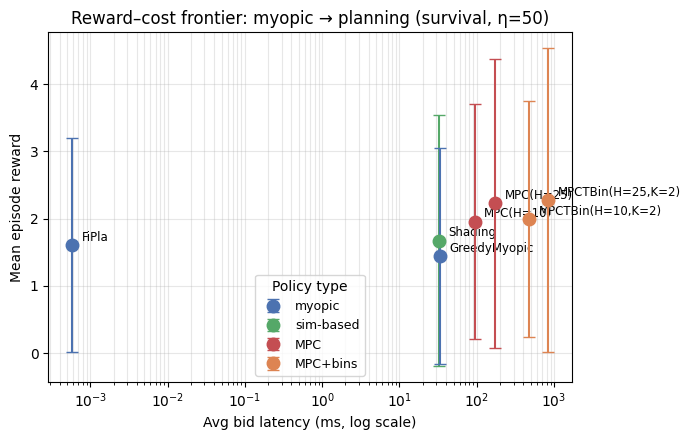

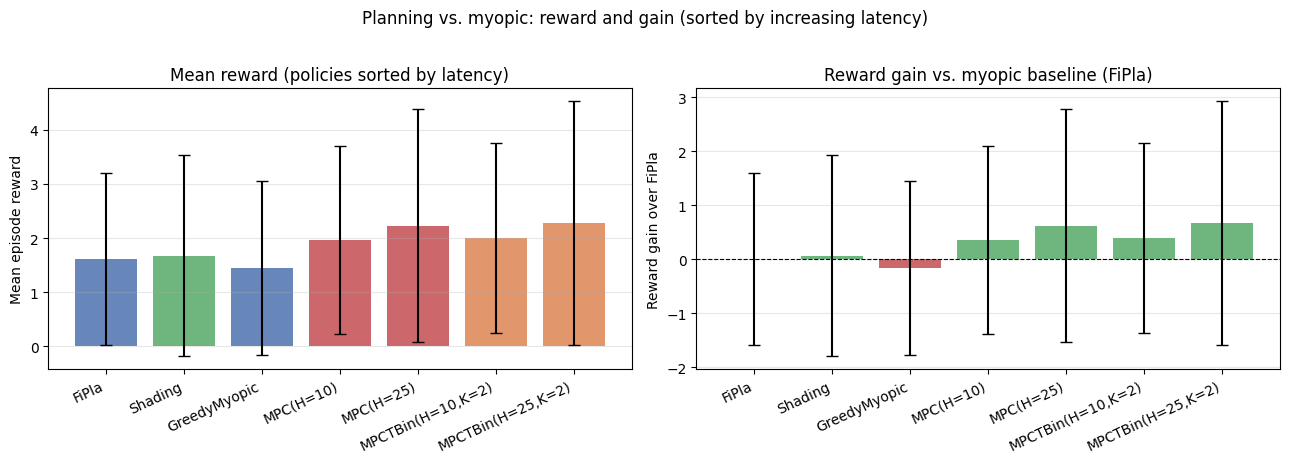

In [7]:
_cat_color = {
    'FiPla': ('myopic', '#4C72B0'),
    'GreedyMyopic': ('myopic', '#4C72B0'),
    'Shading(α=0.7)': ('sim-based', '#55A868'),
    'MPC(H=10)': ('MPC', '#C44E52'),
    'MPC(H=25)': ('MPC', '#C44E52'),
    'MPCTimeBinned(H=10,K=2)': ('MPC+bins', '#DD8452'),
    'MPCTimeBinned(H=25,K=2)': ('MPC+bins', '#DD8452'),
}
_short = {p: p.replace('MPCTimeBinned', 'MPCTBin').replace('Shading(α=0.7)', 'Shading')
          for p in _non_rl['policy']}

# ── Plot A: Pareto scatter (latency vs reward) ──────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4.5))
_seen = set()
for _, row in _non_rl.iterrows():
    cat, c = _cat_color.get(row['policy'], ('other', 'grey'))
    lbl = cat if cat not in _seen else '_nolegend_'
    _seen.add(cat)
    ax.errorbar(row['avg_bid_ms'], row['mean_reward'], yerr=row['std_reward'],
                fmt='o', color=c, capsize=4, markersize=9, label=lbl, zorder=3)
    ax.annotate(_short[row['policy']], (row['avg_bid_ms'], row['mean_reward']),
                textcoords='offset points', xytext=(7, 3), fontsize=8.5)
ax.set_xlabel('Avg bid latency (ms, log scale)')
ax.set_ylabel('Mean episode reward')
ax.set_xscale('log')
ax.set_title('Reward–cost frontier: myopic → planning (survival, η=50)')
ax.legend(title='Policy type', fontsize=9)
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.savefig('planning_vs_myopic_scatter.pdf')
plt.show()

# ── Plot B: grouped bar chart (reward + reward gain sorted by latency) ──────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
_polnames = [_short[p] for p in _non_rl['policy']]
_colors2  = [_cat_color.get(p, ('', 'grey'))[1] for p in _non_rl['policy']]
_x2 = np.arange(len(_non_rl))

axes[0].bar(_x2, _non_rl['mean_reward'], color=_colors2, alpha=0.85,
            yerr=_non_rl['std_reward'], capsize=4)
axes[0].set_xticks(_x2); axes[0].set_xticklabels(_polnames, rotation=25, ha='right')
axes[0].set_ylabel('Mean episode reward')
axes[0].set_title('Mean reward (policies sorted by latency)')
axes[0].grid(True, axis='y', alpha=0.3)

_gains = _non_rl['mean_reward'] - _fipla_reward
_bar_colors = ['#C44E52' if g < 0 else '#55A868' for g in _gains]
axes[1].bar(_x2, _gains, color=_bar_colors, alpha=0.85,
            yerr=_non_rl['std_reward'], capsize=4)
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_xticks(_x2); axes[1].set_xticklabels(_polnames, rotation=25, ha='right')
axes[1].set_ylabel('Reward gain over FiPla')
axes[1].set_title('Reward gain vs. myopic baseline (FiPla)')
axes[1].grid(True, axis='y', alpha=0.3)

plt.suptitle('Planning vs. myopic: reward and gain (sorted by increasing latency)', y=1.02)
plt.tight_layout()
plt.savefig('planning_vs_myopic_bars.pdf')
plt.show()

---
## 3. Deep RL vs. MPC: training cost + inference latency

Key distinction:
- **RL**: large one-time training cost (hours), negligible inference (~0.2 ms per bid)
- **MPC**: no RL training needed (only a short MLP pretraining, ~5 min), but expensive per-decision planning (tens to hundreds of ms)

Training times measured by SLURM `sacct` on the Margaret cluster (`normal-best`, 4 CPUs), 10M timesteps.

In [8]:
_rl_train_h = {
    'PPO': 0.8,   # ~44–55 min (sacct, jobs 406386–406403, 10M timesteps, 6 scenarios)
    'SAC': 10.0,  # estimated ~10–12h (still running at 9h41m check)
    'TD3': 9.1,   # ~8.9–9.4h
}
_mlp_train_h = 0.08  # ~5 min MLP pretraining

_rl_latency  = {row['policy']: row['avg_bid_ms']
                for _, row in timing[timing['policy'].isin(['PPO', 'SAC', 'TD3'])].iterrows()}
_mpc_latency = {row['policy']: row['avg_bid_ms']
                for _, row in timing[timing['policy'].isin(_mpc_policies)].iterrows()}

tbl3_rows = []
for algo in ['PPO', 'SAC', 'TD3']:
    tbl3_rows.append({
        'Method': algo, 'Type': 'Deep RL', 'n_rollouts': '—',
        'Training time (h)': _rl_train_h.get(algo, float('nan')),
        'Inference latency (ms)': _rl_latency.get(algo, float('nan')),
    })
for pol in _mpc_policies:
    tbl3_rows.append({
        'Method': pol, 'Type': 'MPC', 'n_rollouts': N_ROLLOUTS.get(pol),
        'Training time (h)': _mlp_train_h,
        'Inference latency (ms)': _mpc_latency.get(pol, float('nan')),
    })

tbl3 = pd.DataFrame(tbl3_rows)

def _fmt_ms(x):
    if pd.isna(x) or (isinstance(x, float) and np.isnan(x)):
        return '—'
    return f'{x:.3f}'

display(
    tbl3.style
    .format({'Training time (h)': '{:.2f}', 'Inference latency (ms)': _fmt_ms})
    .background_gradient(subset=['Training time (h)'], cmap='YlOrRd')
    .background_gradient(subset=['Inference latency (ms)'], cmap='YlOrRd')
    .set_caption('Table 3 — Deep RL vs. MPC: training cost + per-decision inference latency '
                 '(Margaret cluster, normal-best, 4 CPUs; RL: 10M timesteps; MLP pretraining: ~5 min)')
    .set_properties(**{'text-align': 'center'})
)

,Method,Type,n_rollouts,Training time (h),Inference latency (ms)
0,PPO,Deep RL,—,0.80,0.232
1,SAC,Deep RL,—,10.00,0.328
2,TD3,Deep RL,—,9.10,0.365
3,MPC(H=10),MPC,10,0.08,93.655
4,MPC(H=25),MPC,10,0.08,172.811
5,"MPCTimeBinned(H=10,K=2)",MPC,10,0.08,470.206
6,"MPCTimeBinned(H=25,K=2)",MPC,10,0.08,834.841


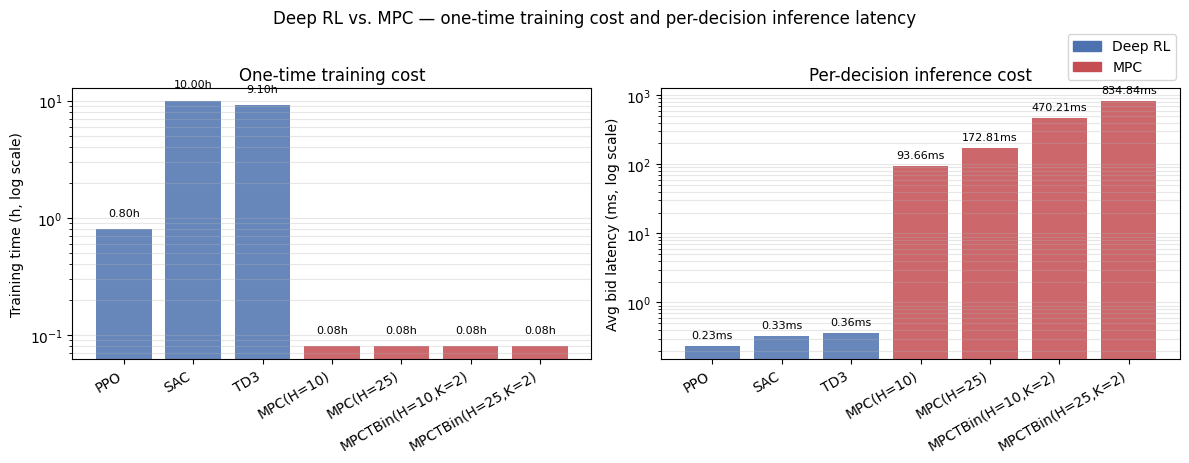

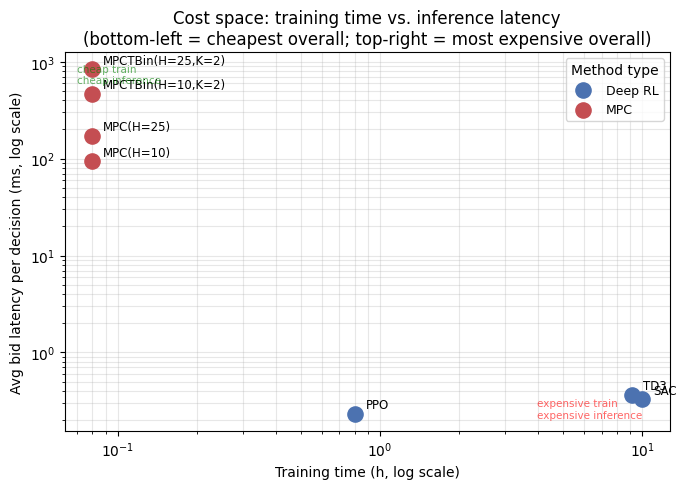

In [9]:
from matplotlib.patches import Patch

_plot_rows = [r for r in tbl3_rows
              if not (isinstance(r['Inference latency (ms)'], float) and np.isnan(r['Inference latency (ms)']))]

if len(_plot_rows) >= 2:
    _short_name = lambda m: m.replace('MPCTimeBinned', 'MPCTBin')
    methods  = [_short_name(r['Method']) for r in _plot_rows]
    train_h  = np.array([r['Training time (h)'] for r in _plot_rows])
    inf_ms   = np.array([r['Inference latency (ms)'] for r in _plot_rows])
    types    = [r['Type'] for r in _plot_rows]
    colors   = ['#4C72B0' if t == 'Deep RL' else '#C44E52' for t in types]
    x        = np.arange(len(methods))

    # ── Plot A: dual bar charts ─────────────────────────────────────────────
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

    ax1.bar(x, train_h, color=colors, alpha=0.85)
    ax1.set_xticks(x); ax1.set_xticklabels(methods, rotation=30, ha='right')
    ax1.set_ylabel('Training time (h, log scale)')
    ax1.set_title('One-time training cost')
    ax1.set_yscale('log')
    ax1.grid(True, axis='y', alpha=0.3, which='both')
    for i, h in enumerate(train_h):
        ax1.text(i, h * 1.3, f'{h:.2f}h', ha='center', fontsize=8)

    ax2.bar(x, inf_ms, color=colors, alpha=0.85)
    ax2.set_xticks(x); ax2.set_xticklabels(methods, rotation=30, ha='right')
    ax2.set_ylabel('Avg bid latency (ms, log scale)')
    ax2.set_title('Per-decision inference cost')
    ax2.set_yscale('log')
    ax2.grid(True, axis='y', alpha=0.3, which='both')
    for i, ms in enumerate(inf_ms):
        ax2.text(i, ms * 1.3, f'{ms:.2f}ms', ha='center', fontsize=8)

    fig.legend(handles=[Patch(color='#4C72B0', label='Deep RL'),
                        Patch(color='#C44E52', label='MPC')],
               loc='upper right', bbox_to_anchor=(0.99, 0.98))
    plt.suptitle('Deep RL vs. MPC — one-time training cost and per-decision inference latency', y=1.02)
    plt.tight_layout()
    plt.savefig('rl_vs_mpc_bars.pdf')
    plt.show()

    # ── Plot B: 2D cost space (training time × inference latency) ───────────
    fig, ax = plt.subplots(figsize=(7, 5))
    _seen_types = set()
    for method, th, ms, tp, c in zip(methods, train_h, inf_ms, types, colors):
        lbl = tp if tp not in _seen_types else '_nolegend_'
        _seen_types.add(tp)
        ax.scatter(th, ms, color=c, s=120, zorder=3, label=lbl)
        ax.annotate(method, (th, ms), textcoords='offset points',
                    xytext=(8, 4), fontsize=8.5)

    ax.set_xlabel('Training time (h, log scale)')
    ax.set_ylabel('Avg bid latency per decision (ms, log scale)')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title('Cost space: training time vs. inference latency\n'
                 '(bottom-left = cheapest overall; top-right = most expensive overall)')
    ax.legend(title='Method type', fontsize=9)
    ax.grid(True, alpha=0.3, which='both')

    # Annotate quadrants with light diagonal arrow hinting
    _xlim = ax.get_xlim(); _ylim = ax.get_ylim()
    ax.text(0.02, 0.97, 'cheap train\ncheap inference', transform=ax.transAxes,
            fontsize=7.5, color='green', va='top', alpha=0.6)
    ax.text(0.78, 0.03, 'expensive train\nexpensive inference', transform=ax.transAxes,
            fontsize=7.5, color='red', va='bottom', alpha=0.6)

    plt.tight_layout()
    plt.savefig('rl_vs_mpc_cost_space.pdf')
    plt.show()
else:
    print('Waiting for more timing data — rerun after all timing jobs complete.')

---
## 4. Latency and reward vs. number of rollouts

How does the number of Monte Carlo rollouts per decision step affect (a) per-bid latency and (b) episode reward?

Latency should scale roughly linearly with n_rollouts (each rollout is an independent forward simulation).
Reward may plateau once enough rollouts are used to estimate the expected future value accurately.

- **Shading**, **MPC(H=10)**, **MPC(H=25)**: complete sweep — n_rollouts ∈ {1, 5, 10, 25, 50}, 30 seeds.
- **MPCTimeBinned(H=10,K=2)**, **MPCTimeBinned(H=25,K=2)**: partial results — n_rollouts ∈ {1, 5, 10} so far.

All runs: `survival-second-price-exponential`, η=50.

In [10]:
NR_DIR = repo_root / 'benchmark/benchmark_results/timing/nrollouts'

# Load merged files for complete variants, concat individual files for partial ones
_nr_parts = []

for variant, merged in [('shading', 'shading_nrollouts.csv'),
                         ('mpc_h10', 'mpc_h10_nrollouts.csv'),
                         ('mpc_h25', 'mpc_h25_nrollouts.csv')]:
    f = NR_DIR / merged
    if f.exists():
        _nr_parts.append(pd.read_csv(f))
        print(f'  {variant}: loaded merged file ({merged})')

for variant in ['mpcbin_h10', 'mpcbin_h25']:
    files = sorted(NR_DIR.glob(f'{variant}_nr*.csv'))
    if files:
        _df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
        _nr_parts.append(_df)
        nrs = sorted(_df['n_rollouts'].unique())
        print(f'  {variant}: loaded {len(files)} partial files, n_rollouts={nrs}')

nr_all = pd.concat(_nr_parts, ignore_index=True)

# Episode reward: last step's cum_reward per (policy, seed, n_rollouts)
_ep = (nr_all.sort_values('step')
       .groupby(['policy', 'n_rollouts', 'seed'])['cum_reward']
       .last()
       .reset_index()
       .rename(columns={'cum_reward': 'ep_reward'}))

# Avg bid latency per (policy, n_rollouts)
_lat = (nr_all.groupby(['policy', 'n_rollouts'])['bid_time_s']
        .mean().mul(1000)
        .reset_index()
        .rename(columns={'bid_time_s': 'avg_bid_ms'}))

nr_summary = (
    _ep.groupby(['policy', 'n_rollouts'])
    .agg(mean_reward=('ep_reward', 'mean'), std_reward=('ep_reward', 'std'))
    .reset_index()
    .merge(_lat, on=['policy', 'n_rollouts'])
    .sort_values(['policy', 'n_rollouts'])
    .reset_index(drop=True)
)
print(f'\nLoaded {len(nr_all)} rows → {len(nr_summary)} (policy, n_rollouts) combinations')

  shading: loaded merged file (shading_nrollouts.csv)
  mpc_h10: loaded merged file (mpc_h10_nrollouts.csv)
  mpc_h25: loaded merged file (mpc_h25_nrollouts.csv)
  mpcbin_h10: loaded 3 partial files, n_rollouts=[np.int64(1), np.int64(5), np.int64(10)]
  mpcbin_h25: loaded 3 partial files, n_rollouts=[np.int64(1), np.int64(5), np.int64(10)]

Loaded 25347 rows → 21 (policy, n_rollouts) combinations


In [11]:
_tbl_nr = nr_summary[['policy', 'n_rollouts', 'mean_reward', 'std_reward', 'avg_bid_ms']].copy()
_tbl_nr.columns = ['Policy', 'n_rollouts', 'Mean reward', 'Std reward', 'Avg bid latency (ms)']

display(
    _tbl_nr.style
    .format({'Mean reward': '{:.3f}', 'Std reward': '{:.3f}', 'Avg bid latency (ms)': '{:.1f}'})
    .background_gradient(subset=['Mean reward'], cmap='YlGn')
    .background_gradient(subset=['Avg bid latency (ms)'], cmap='YlOrRd')
    .set_caption('Table 4 — Latency and reward vs. n_rollouts '
                 '(survival-second-price-exponential, η=50, 30 seeds; '
                 'mpcbin variants: n_rollouts ∈ {1,5,10} only)')
    .set_properties(**{'text-align': 'center'})
)

,Policy,n_rollouts,Mean reward,Std reward,Avg bid latency (ms)
0,MPC(H=10),1,1.655,1.575,9.4
1,MPC(H=10),5,2.082,2.267,47.5
2,MPC(H=10),10,1.727,1.665,92.2
3,MPC(H=10),25,1.735,1.704,226.4
4,MPC(H=10),50,1.768,1.633,470.2
5,MPC(H=25),1,1.978,2.919,16.8
6,MPC(H=25),5,2.003,2.403,82.9
7,MPC(H=25),10,2.149,2.480,169.5
8,MPC(H=25),25,2.107,2.550,421.1
9,MPC(H=25),50,1.992,2.394,855.7


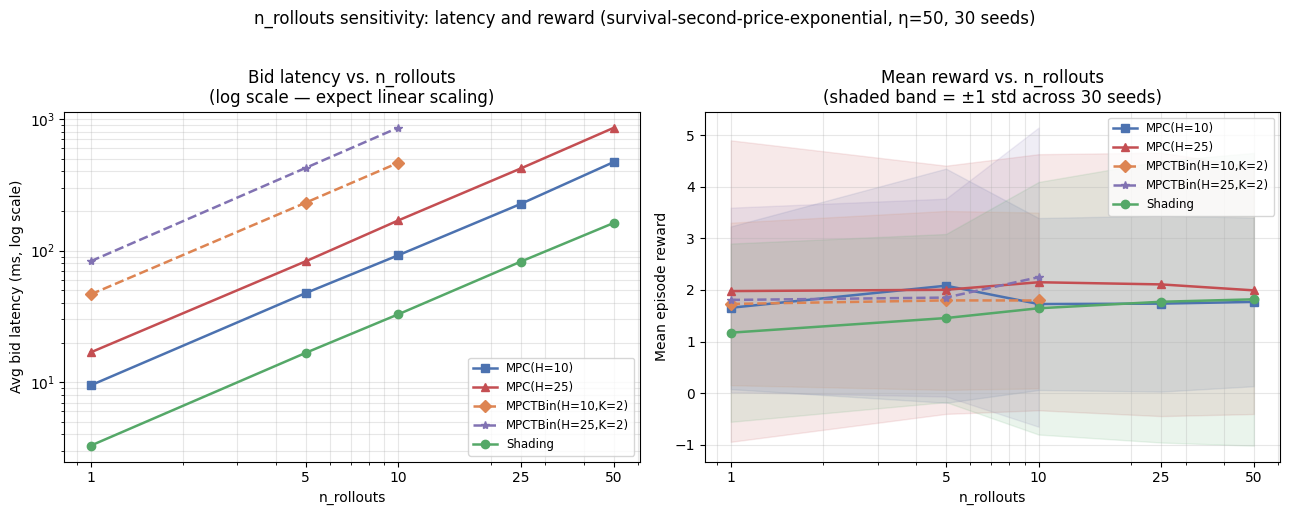

In [12]:
_pol_colors = {
    'Shading(α=0.7)':           '#55A868',
    'MPC(H=10)':                '#4C72B0',
    'MPC(H=25)':                '#C44E52',
    'MPCTimeBinned(H=10,K=2)':  '#DD8452',
    'MPCTimeBinned(H=25,K=2)':  '#8172B2',
}
_pol_style = {
    'Shading(α=0.7)':           '-o',
    'MPC(H=10)':                '-s',
    'MPC(H=25)':                '-^',
    'MPCTimeBinned(H=10,K=2)':  '--D',
    'MPCTimeBinned(H=25,K=2)':  '--*',
}
_short_nr = lambda p: p.replace('MPCTimeBinned', 'MPCTBin').replace('Shading(α=0.7)', 'Shading')

fig, (ax_lat, ax_rew) = plt.subplots(1, 2, figsize=(13, 5))

for pol, grp in nr_summary.groupby('policy'):
    grp = grp.sort_values('n_rollouts')
    c = _pol_colors.get(pol, 'grey')
    fmt = _pol_style.get(pol, '-o')
    label = _short_nr(pol)

    # Left: latency vs n_rollouts (log scale)
    ax_lat.plot(grp['n_rollouts'], grp['avg_bid_ms'], fmt, color=c, label=label,
                linewidth=1.8, markersize=6)

    # Right: reward vs n_rollouts with ±1 std shaded band
    ax_rew.plot(grp['n_rollouts'], grp['mean_reward'], fmt, color=c, label=label,
                linewidth=1.8, markersize=6)
    ax_rew.fill_between(grp['n_rollouts'],
                        grp['mean_reward'] - grp['std_reward'],
                        grp['mean_reward'] + grp['std_reward'],
                        color=c, alpha=0.12)

ax_lat.set_xlabel('n_rollouts')
ax_lat.set_ylabel('Avg bid latency (ms, log scale)')
ax_lat.set_title('Bid latency vs. n_rollouts\n(log scale — expect linear scaling)')
ax_lat.set_yscale('log')
ax_lat.set_xscale('log')
ax_lat.set_xticks([1, 5, 10, 25, 50])
ax_lat.get_xaxis().set_major_formatter(ticker.ScalarFormatter())
ax_lat.legend(fontsize=8.5)
ax_lat.grid(True, alpha=0.3, which='both')

ax_rew.set_xlabel('n_rollouts')
ax_rew.set_ylabel('Mean episode reward')
ax_rew.set_title('Mean reward vs. n_rollouts\n(shaded band = ±1 std across 30 seeds)')
ax_rew.set_xscale('log')
ax_rew.set_xticks([1, 5, 10, 25, 50])
ax_rew.get_xaxis().set_major_formatter(ticker.ScalarFormatter())
ax_rew.legend(fontsize=8.5)
ax_rew.grid(True, alpha=0.3, which='both')

plt.suptitle('n_rollouts sensitivity: latency and reward '
             '(survival-second-price-exponential, η=50, 30 seeds)', y=1.02)
plt.tight_layout()
plt.savefig('nrollouts_sensitivity.pdf')
plt.show()